In [3]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import sys
import importlib

sys.path.append("../src")

import validator
importlib.reload(validator)

from validator import dimension_check
from validator import missing_values_check


## 1. Load PS1 sensor data

Each row represents one measurement cycle, and each column
represents a measurement at a different time point.

In [4]:


data_path = Path("../data/raw/PS1.txt")
ps1 = pd.read_csv(
    data_path,
    sep="\t",
    header=None
)
ps1.head()


,0,1,2,3,4,5,6,7,8,9,...,5990,5991,5992,5993,5994,5995,5996,5997,5998,5999
0,151.47,151.45,151.52,151.27,150.80,150.69,153.89,154.67,152.88,153.82,...,151.16,151.19,151.25,151.16,151.10,151.16,151.14,151.10,151.21,151.19
1,151.11,151.12,151.16,150.92,150.70,150.62,152.40,153.21,152.81,153.53,...,150.82,150.82,150.86,150.80,150.73,150.79,150.84,150.79,150.80,150.86
2,150.81,150.79,150.84,150.65,150.35,150.23,152.03,152.81,152.44,153.27,...,150.49,150.44,150.47,150.46,150.38,150.47,150.50,150.43,150.54,150.62
3,150.48,150.47,150.52,150.31,150.04,149.98,151.63,152.48,152.24,152.94,...,150.34,150.30,150.28,150.38,150.41,150.33,150.31,150.31,150.25,150.28
4,150.41,150.35,150.24,150.12,149.87,149.71,151.64,152.37,151.78,152.68,...,150.31,150.20,150.17,150.28,150.31,150.25,150.27,150.22,150.13,150.19


In [5]:
dimensions = dimension_check(ps1)

print(f"Rows: {dimensions['rows']}")
print(f"Columns: {dimensions['columns']}")
print(f"Total values: {dimensions['total_values']}")

Rows: 2205
Columns: 6000
Total values: 13230000


## 2.Inspect Dataset Structure and Quality

Check the dimensions, missing values, and data types
to understand the structure and initial quality of the data.

In [7]:
dimensions = dimension_check(ps1)
missing = missing_values_check(ps1)

print(f"Numbers of cycles: {dimensions['rows']}")
print(f"Measurements per cycle: {dimensions['columns']}")
print(f"Missing values: {missing}")
print(f"Data types:\n{ps1.dtypes.value_counts()}")


Numbers of cycles: 2205
Measurements per cycle: 6000
Missing values: 0
Data types:
float64    6000
Name: count, dtype: int64


## 3.Descriptive Statistics

Calculate descriptive statistics to understand the distribution
and variability of pressure measurements.

The first analysis examines the first measurement position
across all cycles. The second examines all measurements
within the first cycle.

In [26]:
ps1.describe()

,0,1,2,3,4,5,6,7,8,9,...,5990,5991,5992,5993,5994,5995,5996,5997,5998,5999
count,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,...,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000
mean,148.978467,148.977220,148.966916,148.647410,147.968898,147.511646,149.992000,151.536866,150.853116,151.464689,...,148.976562,148.975782,148.976200,148.977447,148.976726,148.977306,148.978122,148.976844,148.976222,148.977125
std,3.684421,3.685462,3.685930,3.790893,4.023828,4.556763,4.280233,3.527235,3.419919,3.458501,...,3.686761,3.686337,3.688244,3.688526,3.684435,3.683719,3.688438,3.689265,3.682870,3.680577
min,144.920000,144.920000,144.560000,144.440000,141.190000,139.460000,142.770000,146.810000,146.440000,146.840000,...,144.460000,144.940000,144.840000,144.890000,144.940000,144.940000,144.880000,144.860000,144.940000,144.940000
25%,147.060000,147.100000,147.100000,146.180000,145.060000,144.770000,146.630000,149.840000,149.650000,150.310000,...,147.070000,147.070000,147.070000,147.080000,147.080000,147.090000,147.090000,147.070000,147.050000,147.060000
50%,148.560000,148.560000,148.560000,148.340000,148.130000,148.060000,150.560000,151.340000,150.520000,151.280000,...,148.580000,148.580000,148.560000,148.580000,148.560000,148.580000,148.560000,148.560000,148.560000,148.560000
75%,150.980000,150.980000,150.980000,150.870000,150.740000,150.710000,152.660000,153.320000,152.420000,153.160000,...,151.000000,150.980000,151.000000,151.000000,151.000000,150.980000,151.000000,150.980000,150.980000,150.980000
max,188.800000,188.880000,188.970000,188.840000,186.110000,187.000000,189.640000,187.880000,188.130000,188.280000,...,188.970000,189.070000,188.960000,188.880000,188.930000,188.910000,188.940000,188.950000,188.850000,188.880000


In [42]:
# Compare the first measurement position across all cycles
ps1.iloc[:, 0].describe()

count    2205.000000
mean      148.978467
std         3.684421
min       144.920000
25%       147.060000
50%       148.560000
75%       150.980000
max       188.800000
Name: 0, dtype: float64

In [43]:
# Examine all pressure measurements within the first cycle
ps1.iloc[0, :].describe()

count    6000.000000
mean      160.673492
std        13.939309
min       145.830000
25%       151.190000
50%       156.250000
75%       166.310000
max       191.510000
Name: 0, dtype: float64

## PS1 Sensor Data Visualization

The PS1 sensor measures hydraulic pressure in bar at a sampling frequency of **100 Hz**, meaning 100 measurements are recorded per second.

Each measurement cycle lasts **60 seconds**. Therefore, the number of measurements per cycle is:

$$
60 \text{ seconds} \times 100 \frac{\text{measurements}}{\text{second}}
= 6{,}000 \text{ measurements}
$$

The dataset contains **2,205 cycles**, with **6,000 measurements per cycle**.

In the raw data:

* Each **row** represents one cycle.
* Each **column** represents a measurement at a different time point within that cycle.

### Pressure Over Time — First Cycle

The chart below shows how hydraulic pressure changes over time during the first cycle.


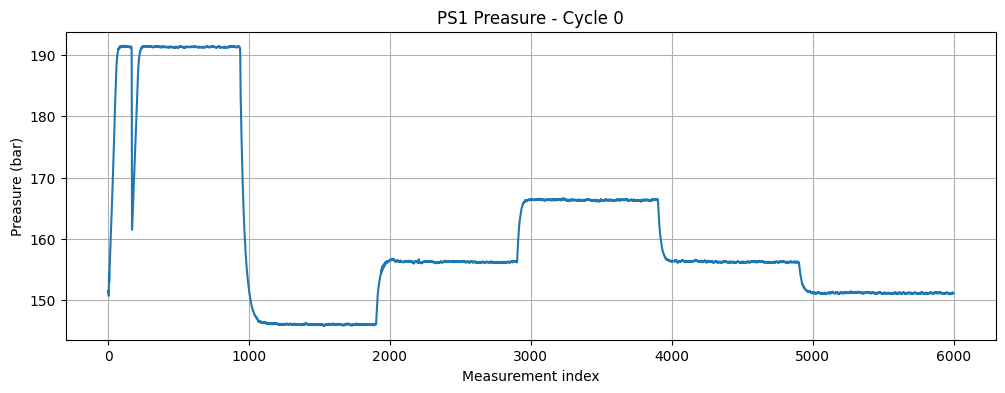

In [57]:
first_cycle = ps1.iloc[0,:]

plt.figure(figsize=(12,4))
plt.plot(first_cycle)
plt.title("PS1 Preasure - Cycle 0")
plt.xlabel("Measurement index")
plt.ylabel("Preasure (bar)")
plt.grid(True)
plt.show()